# El caso de las cucharas desaparecidas

Lim, Hellard y Aitken (2005) colocaron 70 cucharas numeradas en las ocho cocinas de un instituto de unos 140 empleados e hicieron un censo semanal durante cinco meses. De las 70 cucharas desaparecieron 56. Aquí usamos el censo por tipo de cocina (comunales y de grupo) para construir y ajustar un modelo de pérdida, y revisamos críticamente las cifras del estudio.

**Contenido**

1. Un sistema dinámico discreto y su vida media.
2. Ajuste de parámetros con el censo.
3. La tasa por cucharas-día.
4. ¿Importa el valor de la cuchara? Qué dice (y qué no) un valor $p$.
5. Una extrapolación a toda la ciudad.

In [1]:
# ============================================================
# Bibliotecas y datos
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats      # distribuciones y pruebas estadísticas

plt.rcParams.update({"figure.dpi": 100, "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.3})

# Censo semanal: número de cucharas presentes en la semana n.
semana = np.arange(23)
comunales = np.array([20, 18, 16, 13, 12, 12, 11, 8, 8, 6, 5, 5, 5, 4, 3, 3, 2, 2, 2, 2, 2, 2, 2])
grupales = np.array([50, 47, 43, 42, 39, 35, 34, 31, 30, 28, 28, 24, 22, 22, 22, 19, 18, 18, 16, 15, 13, 13, 12])
COCINAS = {"comunales": comunales, "grupales": grupales}

print(f"Perdidas: comunales = {comunales[0] - comunales[-1]}, grupales = {grupales[0] - grupales[-1]},"
      f" total = {comunales[0] - comunales[-1] + grupales[0] - grupales[-1]} de 70")

Perdidas: comunales = 18, grupales = 38, total = 56 de 70


## 1. Un sistema dinámico discreto

**(a)** Si cada semana desaparece una fracción $r$ de las cucharas presentes,

$$
N_{n+1} = N_n - rN_n = (1 - r)\,N_n .
$$

$r$ es la **probabilidad de que una cuchara dada desaparezca durante una semana** (o, para muchas cucharas, la fracción que desaparece). Solo tiene sentido $0 \le r \le 1$: con $r < 0$ aparecerían cucharas de la nada, y con $r > 1$ el número de cucharas sería negativo. Con $r = 0$ no se pierde ninguna; con $r = 1$ desaparecen todas en una semana.

**(b)** La solución es $N_n = N_0(1-r)^n$. Se comprueba sustituyendo: si $N_n = N_0(1-r)^n$, entonces $(1-r)N_n = N_0(1-r)^{n+1} = N_{n+1}$; y para $n = 0$ da $N_0$. Por inducción, es la solución para todo $n$.

**(c)** La vida media $t_{1/2}$ cumple $N_0(1-r)^{t_{1/2}} = N_0/2$. Tomando logaritmos, $t_{1/2}\ln(1-r) = -\ln 2$, de modo que

$$
t_{1/2} = \frac{\ln 2}{-\ln(1 - r)} \quad\text{semanas}.
$$

Como $0 < 1 - r < 1$, el logaritmo es negativo y $t_{1/2} > 0$. Cuanto mayor es $r$, más negativo es $\ln(1-r)$ y más corta la vida media. Para $r$ pequeño, $-\ln(1-r) \approx r$ y $t_{1/2} \approx 0.693/r$: duplicar la tasa de pérdida divide la vida media entre dos. La vida media **no depende de** $N_0$: es la misma para 20 que para 50 cucharas, una propiedad de todo decaimiento exponencial.

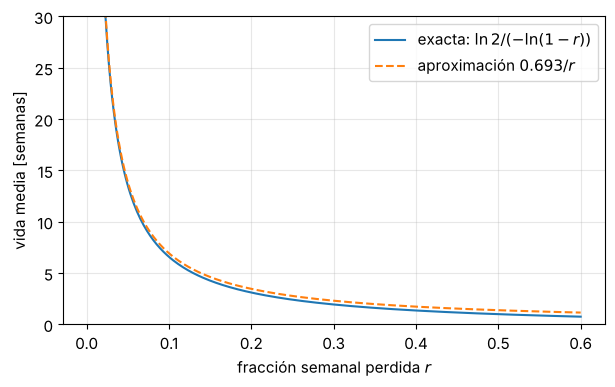

In [2]:
r = np.linspace(0.001, 0.6, 300)
plt.figure(figsize=(7, 4))
plt.plot(r, np.log(2) / -np.log(1 - r), label=r"exacta: $\ln 2 / (-\ln(1-r))$")
plt.plot(r, np.log(2) / r, "--", label=r"aproximación $0.693/r$")
plt.ylim(0, 30)
plt.xlabel("fracción semanal perdida $r$")
plt.ylabel("vida media [semanas]")
plt.legend()
plt.show()

## 2. Ajuste de parámetros

**Método 1: regresión lineal en escala logarítmica.** Como $\ln N_n = \ln N_0 + n\ln(1-r)$, los puntos $(n, \ln N_n)$ deben caer cerca de una recta con pendiente $s = \ln(1 - r)$; de ahí $\hat r = 1 - e^{s}$.

**Método 2: máxima verosimilitud.** Pensemos en cada cuchara presente al inicio de la semana $n$ como un volado con probabilidad $r$ de desaparecer. Las pérdidas de esa semana, $D_n = N_n - N_{n+1}$, siguen entonces una distribución binomial con $N_n$ intentos y probabilidad $r$. Maximizando la verosimilitud de todas las semanas se obtiene un estimador muy intuitivo:

$$
\hat r = \frac{\sum_n D_n}{\sum_n N_n} = \frac{\text{cucharas perdidas}}{\text{cucharas-semana observadas}},
$$

con error estándar aproximado $\sqrt{\hat r(1 - \hat r)/\sum_n N_n}$. (Este estimador ya es una "tasa por cucharas-tiempo", que es justamente el tema de la sección 3.)

Los dos métodos pesan los datos de forma distinta: la regresión en logaritmos da el mismo peso a cada semana, aunque en las últimas semanas de las cocinas comunales solo queden 2 cucharas; la máxima verosimilitud da más peso a las semanas con más cucharas, que tienen más información.

In [3]:
def ajuste_log(N):
    """Método 1: recta de mínimos cuadrados de ln N contra n. Regresa r, pendiente, ordenada."""
    n = np.arange(len(N))
    pendiente, ordenada = np.polyfit(n, np.log(N), deg=1)
    return 1 - np.exp(pendiente), pendiente, ordenada


def ajuste_mv(N):
    """
    Método 2: máxima verosimilitud binomial.
    Pérdidas de cada semana D_n = N_n - N_{n+1}; cucharas en riesgo = N_n (n = 0, ..., 21).
    Regresa r y su error estándar.
    """
    perdidas = N[:-1] - N[1:]
    en_riesgo = N[:-1]
    r_hat = perdidas.sum() / en_riesgo.sum()
    ee = np.sqrt(r_hat * (1 - r_hat) / en_riesgo.sum())
    return r_hat, ee


def vida_media_semanas(r):
    """t_1/2 = ln 2 / (-ln(1 - r)) en semanas."""
    return np.log(2) / -np.log(1 - r)


REPORTADO = {"comunales": 42, "grupales": 77}   # vida media del estudio, en días
resultados = {}
for nombre, N in COCINAS.items():
    r_log, s, b = ajuste_log(N)
    r_mv, ee = ajuste_mv(N)
    resultados[nombre] = dict(r_log=r_log, r_mv=r_mv, ee=ee, s=s, b=b)
    print(f"Cocinas {nombre}:")
    print(f"   método 1 (log-lineal):      r = {r_log:.4f}  -> vida media = {vida_media_semanas(r_log):5.2f} semanas = {7 * vida_media_semanas(r_log):5.1f} días")
    lo, hi = r_mv - 1.96 * ee, r_mv + 1.96 * ee
    print(f"   método 2 (máx. verosim.):   r = {r_mv:.4f} (IC 95%: {lo:.4f}–{hi:.4f})"
          f" -> vida media = {7 * vida_media_semanas(r_mv):5.1f} días (IC: {7 * vida_media_semanas(hi):.0f}–{7 * vida_media_semanas(lo):.0f})")
    print(f"   reportado por el estudio:                                   {REPORTADO[nombre]} días\n")

Cocinas comunales:
   método 1 (log-lineal):      r = 0.1122  -> vida media =  5.82 semanas =  40.8 días
   método 2 (máx. verosim.):   r = 0.1118 (IC 95%: 0.0631–0.1605) -> vida media =  40.9 días (IC: 28–74)
   reportado por el estudio:                                   42 días

Cocinas grupales:
   método 1 (log-lineal):      r = 0.0618  -> vida media = 10.86 semanas =  76.0 días
   método 2 (máx. verosim.):   r = 0.0624 (IC 95%: 0.0432–0.0816) -> vida media =  75.3 días (IC: 57–110)
   reportado por el estudio:                                   77 días



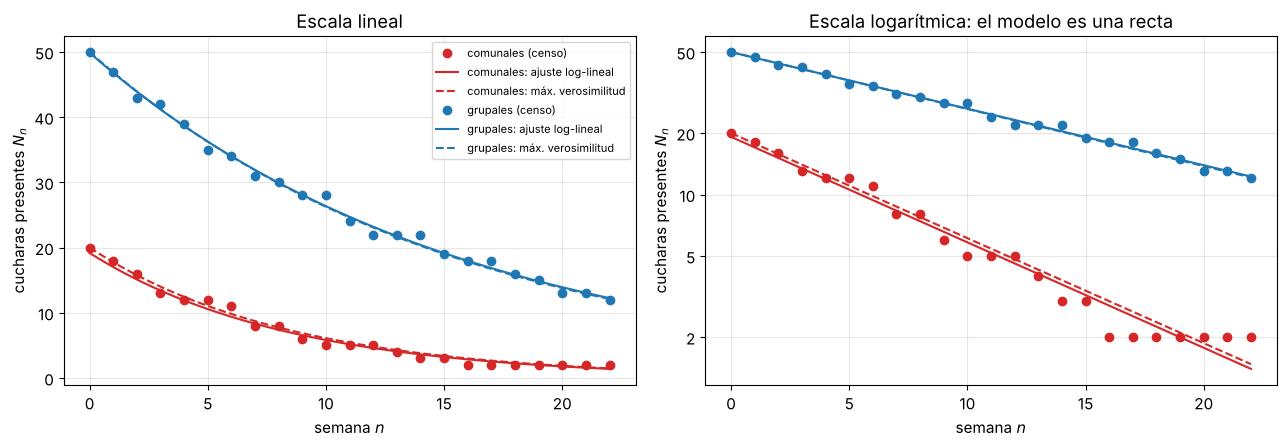

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
nn = np.linspace(0, 22, 200)
for (nombre, N), c in zip(COCINAS.items(), ["C3", "C0"]):
    R = resultados[nombre]
    for ax in axs:
        ax.plot(semana, N, "o", color=c, label=f"{nombre} (censo)")
        ax.plot(nn, np.exp(R["b"] + R["s"] * nn), "-", color=c, lw=1.5, label=f"{nombre}: ajuste log-lineal")
        ax.plot(nn, N[0] * (1 - R["r_mv"]) ** nn, "--", color=c, lw=1.5, label=f"{nombre}: máx. verosimilitud")
axs[0].set_title("Escala lineal")
axs[1].set_yscale("log")
axs[1].set_yticks([2, 5, 10, 20, 50], labels=["2", "5", "10", "20", "50"])   # marcas legibles
axs[1].minorticks_off()
axs[1].set_title("Escala logarítmica: el modelo es una recta")
for ax in axs:
    ax.set_xlabel("semana $n$")
    ax.set_ylabel("cucharas presentes $N_n$")
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**¿Qué tan cerca llegamos y por qué no debe esperarse un acuerdo exacto?** Muy cerca: unos 41 días para las cocinas comunales (reportado: 42) y unos 75–76 días para las de grupo (reportado: 77), con los dos métodos. Las cocinas comunales pierden cucharas casi el doble de rápido. Pero los intervalos de confianza son anchos (de 28 a 74 días para las comunales), así que una coincidencia de uno o dos días es en buena medida suerte. No hay que esperar un acuerdo exacto por varias razones:

* **Ruido de números pequeños.** Con 20 cucharas comunales, una o dos pérdidas de más o de menos cambian bastante la estimación.
* **El modelo no es perfecto.** En las cocinas comunales las últimas 2 cucharas sobreviven siete semanas seguidas: o la tasa no es constante (quedan las cucharas "menos atractivas" o mejor escondidas) o simplemente es azar con números muy pequeños. La regresión en logaritmos es sensible a esa meseta.
* **Métodos diferentes.** El estudio estimó las vidas medias siguiendo cucharas individuales con métodos de supervivencia, no ajustando una exponencial a esta tabla agregada.
* **Discretización.** Solo sabemos en qué semana desapareció cada cuchara, no el día exacto.

## 3. La tasa por cucharas-día

**(a) ¿Por qué "por cucharas-día" y no "por día"?** Porque el número de cucharas que pueden perderse **disminuye** con el tiempo. Al principio había 70 cucharas expuestas; al final, 14. Decir "se pierden 0.4 cucharas por día" no tiene sentido como parámetro, porque ese número depende de cuántas cucharas quedaban. Lo constante (según el modelo) es la probabilidad de pérdida **por cuchara** y por unidad de tiempo. Dividir las pérdidas entre las cucharas-día observadas (la suma, día por día, de las cucharas presentes) corrige por esa exposición decreciente. Es la misma idea que las "personas-año" en epidemiología.

In [5]:
# (b) Total de cucharas-día y tasa por 100 cucharas-día con los datos de la tabla.
perdidas_total = (comunales[0] - comunales[-1]) + (grupales[0] - grupales[-1])
cs_dias_todo = 7 * (comunales.sum() + grupales.sum())                 # semanas 0 a 22
cs_dias_riesgo = 7 * (comunales[:-1].sum() + grupales[:-1].sum())     # semanas 0 a 21
print(f"Cucharas perdidas: {perdidas_total}")
print(f"Cucharas-día (suma de las 23 semanas x 7): {cs_dias_todo}"
      f"  -> tasa = {100 * perdidas_total / cs_dias_todo:.3f} por 100 cucharas-día")
print(f"Cucharas-día (sin la última semana, x 7):  {cs_dias_riesgo}"
      f"  -> tasa = {100 * perdidas_total / cs_dias_riesgo:.3f} por 100 cucharas-día")
print(f"Estudio:                                   5668  -> tasa = 0.99 (IC 95% 0.76–1.28)")

Cucharas perdidas: 56
Cucharas-día (suma de las 23 semanas x 7): 5488  -> tasa = 1.020 por 100 cucharas-día
Cucharas-día (sin la última semana, x 7):  5390  -> tasa = 1.039 por 100 cucharas-día
Estudio:                                   5668  -> tasa = 0.99 (IC 95% 0.76–1.28)


Obtenemos unas 5 400–5 500 cucharas-día y una tasa de alrededor de 1.0–1.04 por 100 cucharas-día, muy cerca de lo reportado (5 668 y 0.99, que además cae dentro del intervalo del estudio). La diferencia en cucharas-día es razonable: el estudio contó días exactos de observación por cuchara, y nosotros solo conocemos censos semanales.

In [6]:
# (c) Fracción diaria de pérdida en cocinas comunales y tasa por 100 cucharas-día.
for nombre in COCINAS:
    r_sem = resultados[nombre]["r_mv"]
    frac_diaria = 1 - (1 - r_sem) ** (1 / 7)
    print(f"{nombre:9s}: r semanal = {r_sem:.4f} -> fracción diaria = {frac_diaria:.5f}"
          f" -> {100 * frac_diaria:.2f} por 100 cucharas-día")

# Tasa conjunta como promedio ponderado por la exposición de cada tipo de cocina.
exp_c, exp_g = 7 * comunales[:-1].sum(), 7 * grupales[:-1].sum()
print(f"\nExposición: comunales = {exp_c} cucharas-día ({100 * exp_c / (exp_c + exp_g):.0f} %),"
      f" grupales = {exp_g} cucharas-día ({100 * exp_g / (exp_c + exp_g):.0f} %)")

comunales: r semanal = 0.1118 -> fracción diaria = 0.01679 -> 1.68 por 100 cucharas-día
grupales : r semanal = 0.0624 -> fracción diaria = 0.00916 -> 0.92 por 100 cucharas-día

Exposición: comunales = 1127 cucharas-día (21 %), grupales = 4263 cucharas-día (79 %)


La tasa de las cocinas comunales (alrededor de 1.7 por 100 cucharas-día) es mucho mayor que 0.99, y **no hay contradicción**: 0.99 es la tasa **global**, que mezcla los dos tipos de cocina. Es un promedio ponderado por la exposición, y las cocinas de grupo aportan casi el 80 % de las cucharas-día (tenían más cucharas y las perdieron más despacio). El promedio (≈ 1.0) queda mucho más cerca de la tasa de las cocinas de grupo (≈ 0.92) que de la de las comunales (≈ 1.68). Una tasa global puede esconder subgrupos muy distintos.

## 4. ¿Importa el valor de la cuchara?

De las 56 perdidas, 12 eran de mejor calidad y 44 estándar. Si el valor no importara, se esperaba perder 12.4 y 43.6 (en proporción a cuántas había de cada tipo). La prueba dio $P = 0.88$.

**(a)** Un valor $p$ es la probabilidad de observar una diferencia **al menos tan grande** como la observada **si la hipótesis nula fuera cierta** (aquí: el valor no afecta la pérdida). $P = 0.88$ significa que, si el valor no importara, en el 88 % de los estudios veríamos diferencias tan grandes o mayores que la observada. Los datos son **perfectamente compatibles** con que el valor no importe; no hay ninguna evidencia de que importe.

Cuidado con dos errores frecuentes: $P = 0.88$ **no** es "la probabilidad de que la hipótesis nula sea cierta", y no rechazar la hipótesis nula **no demuestra** que sea cierta.

**(b)** La diferencia (12 contra 12.4) es de menos de media cuchara: es mucho menor que la variación esperable por azar. Con 56 pérdidas, el número de cucharas de calidad perdidas variaría típicamente en unas $\pm 3$ de un estudio a otro aunque no hubiera ningún efecto. Así que **no importa**: es ruido.

In [7]:
observado = np.array([12, 44])
esperado = np.array([12.4, 43.6])
chi2 = np.sum((observado - esperado) ** 2 / esperado)
p_chi2 = stats.chi2.sf(chi2, df=1)
print(f"chi^2 = {chi2:.4f}, valor p (chi cuadrada, 1 g.l.) = {p_chi2:.3f}")
p_binom = stats.binomtest(12, n=56, p=12.4 / 56).pvalue
print(f"valor p (prueba binomial exacta)          = {p_binom:.3f}")
print(f"desviación estándar esperada por azar: ±{np.sqrt(56 * (12.4 / 56) * (1 - 12.4 / 56)):.1f} cucharas")

chi^2 = 0.0166, valor p (chi cuadrada, 1 g.l.) = 0.898
valor p (prueba binomial exacta)          = 1.000
desviación estándar esperada por azar: ±3.1 cucharas


Nuestro cálculo da $p \approx 0.90$ con la chi cuadrada y $p = 1$ con la prueba binomial exacta; el 0.88 del estudio probablemente viene de otra prueba (por ejemplo, comparando tasas por cucharas-día). La conclusión es la misma con cualquiera de ellas.

**¿El estudio podía detectar un efecto, si lo hubiera?** Esa es la pregunta de la **potencia**. Simulamos estudios con 56 pérdidas en los que las cucharas de calidad se pierden con un riesgo relativo $RR$ respecto a las estándar y vemos con qué frecuencia la prueba daría $p < 0.05$.

In [8]:
rng = np.random.default_rng(5)
frac_calidad = 12.4 / 56          # fracción de cucharas de calidad en el inventario


def potencia(RR, n_perdidas=56, n_sim=20000):
    """
    Probabilidad de obtener p < 0.05 (chi cuadrada) si las cucharas de calidad
    se pierden con riesgo relativo RR. Entre las cucharas perdidas, la fracción
    de calidad es q = f RR / (f RR + (1 - f)).
    """
    q = frac_calidad * RR / (frac_calidad * RR + 1 - frac_calidad)
    calidad = rng.binomial(n_perdidas, q, size=n_sim)
    obs = np.stack([calidad, n_perdidas - calidad], axis=1)
    esp = n_perdidas * np.array([frac_calidad, 1 - frac_calidad])
    chi = ((obs - esp) ** 2 / esp).sum(axis=1)
    return np.mean(stats.chi2.sf(chi, df=1) < 0.05)


for RR in [0.5, 0.67, 1.0, 1.5, 2.0, 3.0]:
    print(f"RR = {RR:4.2f}: potencia ≈ {potencia(RR):.2f}")

RR = 0.50: potencia ≈ 0.44
RR = 0.67: potencia ≈ 0.19
RR = 1.00: potencia ≈ 0.05
RR = 1.50: potencia ≈ 0.30
RR = 2.00: potencia ≈ 0.69
RR = 3.00: potencia ≈ 0.98


Con 56 pérdidas, el estudio solo detectaba casi siempre efectos enormes (riesgo triple: potencia ≈ 0.98). Si las cucharas de calidad se perdieran el doble, la prueba lo detectaría en ~70 % de los estudios; si se perdieran la mitad, solo en ~44 %; y un 50 % más de riesgo pasaría inadvertido en ~70 % de los casos. La conclusión correcta es "no encontramos evidencia de que el valor importe, y podemos descartar efectos muy grandes", no "el valor no importa".

## 5. Extrapolación: un *sanity check*

Los autores extrapolaron a la fuerza laboral de Melbourne (unos 2.5 millones de personas): 18 millones de cucharas perdidas al año, que puestas en fila cubrirían más de 2 700 km y pesarían más de 360 toneladas.

In [9]:
n_cucharas = 18e6
largo_m = 2700e3 / n_cucharas
masa_g = 360e6 / n_cucharas       # 360 toneladas = 360e6 gramos
print(f"(a) Longitud por cuchara: {100 * largo_m:.1f} cm;  masa por cuchara: {masa_g:.0f} g")

# ¿Cuántas cucharas por trabajador implica? ¿Y qué dan los datos del instituto?
por_trabajador = n_cucharas / 2.5e6
tasa_dia = 56 / 5668                              # por cuchara-día (estudio)
cucharas_por_empleado = 70 / 140                  # inventario del instituto
perdidas_empleado_anio = tasa_dia * 365 * cucharas_por_empleado
print(f"\n18 millones / 2.5 millones de trabajadores = {por_trabajador:.1f} cucharas por trabajador al año")
print(f"Con la tasa del estudio ({100 * tasa_dia:.2f} por 100 cucharas-día) y 0.5 cucharas por empleado,"
      f" se pierden {perdidas_empleado_anio:.1f} cucharas por empleado al año")
print(f"-> extrapolación directa: {perdidas_empleado_anio * 2.5e6 / 1e6:.1f} millones de cucharas al año en Melbourne")

(a) Longitud por cuchara: 15.0 cm;  masa por cuchara: 20 g

18 millones / 2.5 millones de trabajadores = 7.2 cucharas por trabajador al año
Con la tasa del estudio (0.99 por 100 cucharas-día) y 0.5 cucharas por empleado, se pierden 1.8 cucharas por empleado al año
-> extrapolación directa: 4.5 millones de cucharas al año en Melbourne


**(a)** 15 cm y 20 g por cuchara: **ambos son razonables** para una cuchara cafetera de acero. Las conversiones a kilómetros y toneladas son internamente consistentes.

Lo interesante es el número de partida. Con la tasa del estudio y el inventario del instituto (media cuchara por empleado, repuesta conforme se pierde), la extrapolación más directa da unos 4.5 millones de cucharas al año, unas cuatro veces menos que 18 millones. Para llegar a 18 millones se necesitan unas 7 cucharas perdidas por trabajador al año. No sabemos exactamente qué supuestos usaron los autores, pero el ejercicio muestra lo sensible que es la extrapolación a supuestos que no se miden en el estudio.

**(b) Supuestos necesarios** para que la extrapolación tenga sentido:

1. Todos los trabajadores de la ciudad tienen acceso a cucharas en una cocina de trabajo, con un inventario por persona parecido al del instituto.
2. La tasa de pérdida por cuchara es la misma en cualquier lugar de trabajo (oficinas, hospitales, fábricas, comercios), en cualquier época del año y durante todo el año.
3. Las cucharas perdidas se reponen, de modo que el inventario (y por lo tanto la exposición) se mantiene constante.
4. "Desaparecer de la cocina" equivale a "perderse": la cuchara sale de circulación definitivamente.
5. El comportamiento en un instituto de investigación médica es representativo de toda la fuerza laboral.

**¿Cuál se rompe primero al salir del instituto?** El supuesto 4. Dentro del instituto, una cuchara que se lleva alguien a su escritorio, a otro edificio o a su casa "desaparece" del censo. Pero a escala de ciudad, esa misma cuchara **sigue en Melbourne**: cambió de lugar, no se perdió. La unidad de análisis cambió y la definición de "pérdida" con ella: lo que es una salida para una cocina no es una salida para la ciudad. Muy de cerca le sigue el supuesto 1: una gran parte de la fuerza laboral no tiene una cocina con cucharas compartidas.

**Referencias:** Lim, M. S. C., Hellard, M. E., & Aitken, C. K. (2005). The case of the disappearing teaspoons. *BMJ* 331: 1498–1500. Mattiussi, M. et al. (2020). What the forks? *Med J Aust* 213(11): 521–523.